In [93]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import sys
from pathlib import Path


from sklearn.metrics import mean_absolute_error, mean_squared_error

In [94]:
%load_ext autoreload
%autoreload 2

from przygotowanie_danych_przepompowania import przygotuj_dane_przepompowania_z_opadami

X, y = przygotuj_dane_przepompowania_z_opadami()

train_end = int(len(X) * 0.7)
val_end = int(len(X) * 0.8)

X_train = X.iloc[:train_end]
X_val = X.iloc[train_end:val_end]
X_test = X.iloc[val_end:]

y_train = y.iloc[:train_end]
y_val = y.iloc[train_end:val_end]
y_test = y.iloc[val_end:]

#print("TRAIN:", X_train.shape, X_train.index.min(), X_train.index.max())
#print("VAL:", X_val.shape, X_val.index.min(), X_val.index.max())
#print("TEST:", X_test.shape, X_test.index.min(), X_test.index.max())

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Strefa przepływu: UTC+01:00
Strefa opadów: UTC+01:00


# CATBOOST

Model opadów opisuje spodziewane pompowanie w danych warunkach, a Q97 stanowi granicę alarmową 

In [95]:
# CATBOOST
from catboost import CatBoostRegressor

cb_median = CatBoostRegressor(
    loss_function = "MAE",
    iterations = 500,
    learning_rate = 0.05,
    depth = 5,
    random_seed=42,
    verbose=0
)
cb_median.fit(X_train, y_train)

cb_q97 = CatBoostRegressor(
    loss_function = "Quantile:alpha=0.97",
    iterations = 500,
    learning_rate = 0.05,
    depth = 5,
    random_seed=42,
    verbose=0
)
cb_q97.fit(X_train, y_train)

y_pred_val = cb_median.predict(X_test)
q_val = cb_q97.predict(X_test)

Godziny ponad normę: 86 z 3504


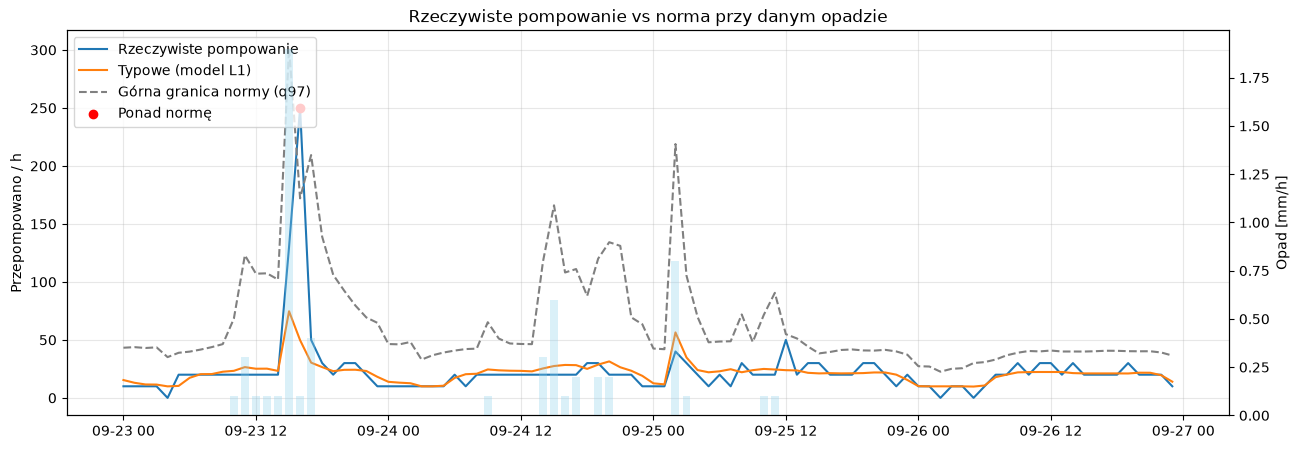

In [96]:
results_val = pd.DataFrame({
    "rzeczywiste": y_test,
    "prognoza": y_pred_val,
    "q97": q_val,
    "opad": X_test["opad_0h"],
    "opad_6h": X_test["opad_6h"],
}, index=y_test.index)

results_val["anomaly"] = results_val["rzeczywiste"] > results_val["q97"]
results_val["ponad_q97"] = (results_val["rzeczywiste"] - results_val["q97"]).clip(lower=0)

print("Godziny ponad normę:", int(results_val["anomaly"].sum()), "z", len(results_val))

sample = results_val.loc["2026-09-23":"2026-09-26"]
alarms = sample[sample["anomaly"]]

fig, ax1 = plt.subplots(figsize=(15, 5))
ax1.plot(sample.index, sample["rzeczywiste"], label="Rzeczywiste pompowanie")
ax1.plot(sample.index, sample["prognoza"], label="Typowe (model L1)")
ax1.plot(sample.index, sample["q97"], "--", color="gray", label="Górna granica normy (q97)")
ax1.scatter(alarms.index, alarms["rzeczywiste"], color="red", zorder=3, label="Ponad normę")
ax1.set_ylabel("Przepompowano / h")

ax2 = ax1.twinx()
ax2.bar(sample.index, sample["opad"], width=0.03, alpha=0.3, color="skyblue", label="Opad [mm/h]")
ax2.set_ylabel("Opad [mm/h]")

ax1.set_title("Rzeczywiste pompowanie vs norma przy danym opadzie")
ax1.legend(loc="upper left")
ax1.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.show()

In [97]:
# Alarm, gdy rzeczywiste pompowanie przekracza Q97
results_val["alarm"] = results_val["anomaly"]

# Nadwyżka względem typowej prognozy pogodowej
results_val["nadwyzka"] = (
    results_val["rzeczywiste"] - results_val["prognoza"]
).clip(lower=0)

print("Liczba godzin alarmowych:", results_val["alarm"].sum())

print(
    "Suma nadwyżek w godzinach alarmowych:",
    round(results_val.loc[results_val["alarm"], "nadwyzka"].sum(), 2)
)

Liczba godzin alarmowych: 86
Suma nadwyżek w godzinach alarmowych: 9855.68


In [98]:
anomalie = results_val[results_val["alarm"]].copy()

#kiedy wystąpiły alarmy, jaka była nadwyżka i czy padało 
display(anomalie[["rzeczywiste", "prognoza", "q97", "nadwyzka", "ponad_q97", "opad", "opad_6h"]])

,rzeczywiste,prognoza,q97,nadwyzka,ponad_q97,opad,opad_6h
Data_czas,,,,,,,
2026-05-20 00:00:00+01:00,20.0,9.948257,18.036411,10.051743,1.963589,0.0,0.0
2026-05-20 08:00:00+01:00,30.0,19.862276,29.149591,10.137724,0.850409,0.0,0.0
2026-05-20 20:00:00+01:00,30.0,20.655811,29.960955,9.344189,0.039045,0.0,0.0
2026-05-20 21:00:00+01:00,30.0,20.652687,29.997865,9.347313,0.002135,0.0,0.0
2026-05-21 06:00:00+01:00,30.0,14.246539,22.203078,15.753461,7.796922,0.0,0.0
...,...,...,...,...,...,...,...
2026-09-21 19:00:00+01:00,260.0,35.058159,168.059680,224.941841,91.940320,0.1,3.2
2026-09-23 16:00:00+01:00,250.0,49.785025,172.066597,200.214975,77.933403,0.1,2.6
2026-10-01 11:00:00+01:00,40.0,28.127804,37.963226,11.872196,2.036774,0.0,0.0


In [115]:

# Ewaluacja na zbiorze testowym
y_pred_test = cb_median.predict(X_test)
q_test = cb_q97.predict(X_test)

mae_test = mean_absolute_error(y_test, y_pred_test)
odsetek_test = (y_test > q_test).mean() * 100

print("MAE TEST:", round(mae_test, 2))
prof = y_train.groupby(y_train.index.hour).median()
base_test = prof.reindex(y_test.index.hour).values
print("MAE baseline:", round(mean_absolute_error(y_test, base_test), 2))
print("Przekroczenia Q97 TEST:", round(odsetek_test, 2), "%")
print("Liczba alarmów TEST:", int((y_test > q_test).sum()))


MAE TEST: 10.29
MAE baseline: 9.76
Przekroczenia Q97 TEST: 2.45 %
Liczba alarmów TEST: 86


In [100]:
from pathlib import Path
from sciezka_projektu import get_project_root
import pandas as pd

DATA_PATH = get_project_root() / "data" / "processed" / "Chorzów"
awarie = pd.read_parquet(DATA_PATH / "awarie.parquet")


In [102]:

# Przygotowanie awarii
awarie["Data_czas"] = pd.to_datetime(
    awarie["Data_czas"], errors="coerce"
)

kolumny_awarii = [
    c for c in awarie.columns
    if c not in ["Data", "Czas", "Data_czas"]
]

for c in kolumny_awarii:
    awarie[c] = pd.to_numeric(
        awarie[c].astype(str)
        .str.replace(",", ".", regex=False)
        .str.strip()
        .replace("-", np.nan),
        errors="coerce"
    )

# 0 oznacza brak aktywnej flagi
# Wykrywamy przejścia z 0 na 1
a = (
    awarie.dropna(subset=["Data_czas"])
    .set_index("Data_czas")
    .sort_index()
)

flagi = a[kolumny_awarii].fillna(0).gt(0)
starty = flagi & ~flagi.shift(1, fill_value=False)

awarie_start = (
    starty.any(axis=1)
    .resample("1h")
    .max()
    .astype("boolean")
    .fillna(False)
    .rename("start_awarii")
)

# Łączenie z wynikami CatBoosta
analiza = results_val.copy()

awarie_start.index = awarie_start.index.tz_localize(
    analiza.index.tz,
    ambiguous="NaT",
    nonexistent="shift_forward"
)
awarie_start = awarie_start[~awarie_start.index.isna()]

analiza = analiza.join(awarie_start, how="left")

# Sprawdzamy, czy awaria wystąpiła +/-12h od alarmu
starty_h = awarie_start.reindex(
    pd.date_range(
        analiza.index.min() - pd.Timedelta(hours=12),
        analiza.index.max() + pd.Timedelta(hours=12),
        freq="1h"
    ),
    fill_value=False
).astype(bool)

blisko = (
    starty_h
    .rolling(25, center=True, min_periods=1)
    .max()
    .astype(bool)
)

analiza["blisko_awarii_12h"] = (
    blisko.reindex(analiza.index, fill_value=False)
)

liczba_alarmow = int(analiza["alarm"].sum())

alarmy_blisko = int(
    (analiza["alarm"] & analiza["blisko_awarii_12h"]).sum()
)

print("Wszystkie godziny alarmowe:", liczba_alarmow)
print("Godziny alarmowe blisko awarii:", alarmy_blisko)
print("Godziny alarmowe bez bliskości awarii:", liczba_alarmow - alarmy_blisko)

display(
    analiza.loc[
        analiza["alarm"],
        ["nadwyzka", "start_awarii", "blisko_awarii_12h"]
    ].head(20)
)


Wszystkie godziny alarmowe: 86
Godziny alarmowe blisko awarii: 60
Godziny alarmowe bez bliskości awarii: 26


,nadwyzka,start_awarii,blisko_awarii_12h
Data_czas,,,
2026-05-20 00:00:00+01:00,10.051743,False,False
2026-05-20 08:00:00+01:00,10.137724,False,False
2026-05-20 20:00:00+01:00,9.344189,False,False
2026-05-20 21:00:00+01:00,9.347313,False,False
2026-05-21 06:00:00+01:00,15.753461,False,False
2026-05-23 09:00:00+01:00,9.956981,False,True
2026-05-23 21:00:00+01:00,10.011646,False,True
2026-05-24 09:00:00+01:00,9.924926,False,False
2026-05-24 15:00:00+01:00,10.020437,False,False


In [103]:
diag_q97 = X_test[["opad_24h"]].copy()

diag_q97["rzeczywiste"] = y_test.to_numpy()
diag_q97["q97"] = q_test

diag_q97["alarm"] = (
    diag_q97["rzeczywiste"] > diag_q97["q97"]
)

diag_q97["warunki"] = np.select(
    [
        diag_q97["opad_24h"].isna(),
        diag_q97["opad_24h"] > 0
    ],
    ["Brak danych", "Mokro"],
    default="Sucho"
)

display(
    diag_q97.groupby("warunki").agg(
        liczba_godzin=("alarm", "size"),
        liczba_alarmow=("alarm", "sum"),
        odsetek_alarmow=("alarm", "mean")
    ).assign(
        odsetek_alarmow=lambda d: d["odsetek_alarmow"] * 100
    )
)

,liczba_godzin,liczba_alarmow,odsetek_alarmow
warunki,,,
Mokro,2251,49,2.176810
Sucho,1253,37,2.952913


In [104]:
kolumny_raportu = [
    "rzeczywiste",
    "prognoza",
    "q97",
    "nadwyzka",
    "ponad_q97",
    "opad",
    "opad_6h",
    "start_awarii",
    "blisko_awarii_12h"
]

raport_godzinowy = analiza.loc[
    analiza["alarm"], kolumny_raportu
].copy()

raport_godzinowy.index.name = "data_godzina"

# Sumujemy nadwyżki wyłącznie w godzinach alarmowych
analiza["nadwyzka_alarmowa"] = analiza["nadwyzka"].where(
    analiza["alarm"], 0
)

raport_dzienny = analiza.resample("1D").agg(
    godziny_alarmow=("alarm", "sum"),
    suma_nadwyzek=("nadwyzka_alarmowa", "sum"),
    opad_mm=("opad", "sum"),
    starty_awarii=("start_awarii", "sum")
)

raport_dzienny = raport_dzienny[
    raport_dzienny["godziny_alarmow"] > 0
]

display(raport_godzinowy.head(20))
display(raport_dzienny.head(20))

,rzeczywiste,prognoza,q97,nadwyzka,ponad_q97,opad,opad_6h,start_awarii,blisko_awarii_12h
data_godzina,,,,,,,,,
2026-05-20 00:00:00+01:00,20.0,9.948257,18.036411,10.051743,1.963589,0.0,0.0,False,False
2026-05-20 08:00:00+01:00,30.0,19.862276,29.149591,10.137724,0.850409,0.0,0.0,False,False
2026-05-20 20:00:00+01:00,30.0,20.655811,29.960955,9.344189,0.039045,0.0,0.0,False,False
2026-05-20 21:00:00+01:00,30.0,20.652687,29.997865,9.347313,0.002135,0.0,0.0,False,False
2026-05-21 06:00:00+01:00,30.0,14.246539,22.203078,15.753461,7.796922,0.0,0.0,False,False
2026-05-23 09:00:00+01:00,30.0,20.043019,29.046210,9.956981,0.953790,0.0,0.0,False,True
2026-05-23 21:00:00+01:00,30.0,19.988354,29.982367,10.011646,0.017633,0.0,0.0,False,True
2026-05-24 09:00:00+01:00,30.0,20.075074,28.971351,9.924926,1.028649,0.0,0.0,False,False
2026-05-24 15:00:00+01:00,30.0,19.979563,29.641472,10.020437,0.358528,0.0,0.0,False,False


,godziny_alarmow,suma_nadwyzek,opad_mm,starty_awarii
Data_czas,,,,
2026-05-20 00:00:00+01:00,4,38.880970,0.300000,0
2026-05-21 00:00:00+01:00,1,15.753461,0.900000,0
2026-05-23 00:00:00+01:00,2,19.968628,0.000000,1
2026-05-24 00:00:00+01:00,2,19.945363,0.300000,0
2026-05-25 00:00:00+01:00,3,29.684062,0.000000,0
2026-05-26 00:00:00+01:00,2,19.981596,0.000000,1
2026-05-27 00:00:00+01:00,3,59.055142,0.300000,2
2026-05-28 00:00:00+01:00,3,29.978199,0.000000,0
2026-05-29 00:00:00+01:00,4,39.999106,0.000000,1


# SHAP

In [105]:
#SHAP
import os
from SHAP import generate_shap_from_tree

# CATBOOST

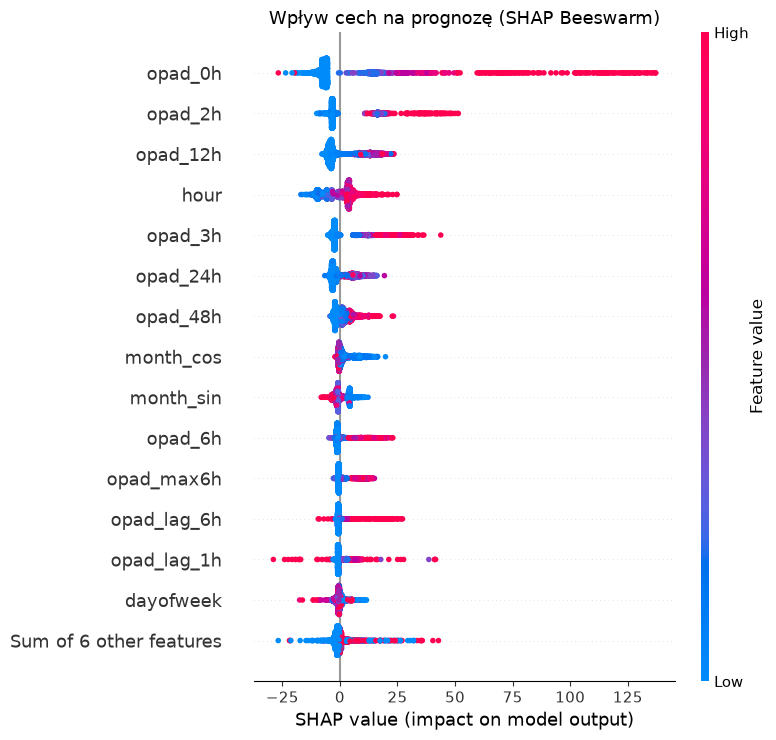

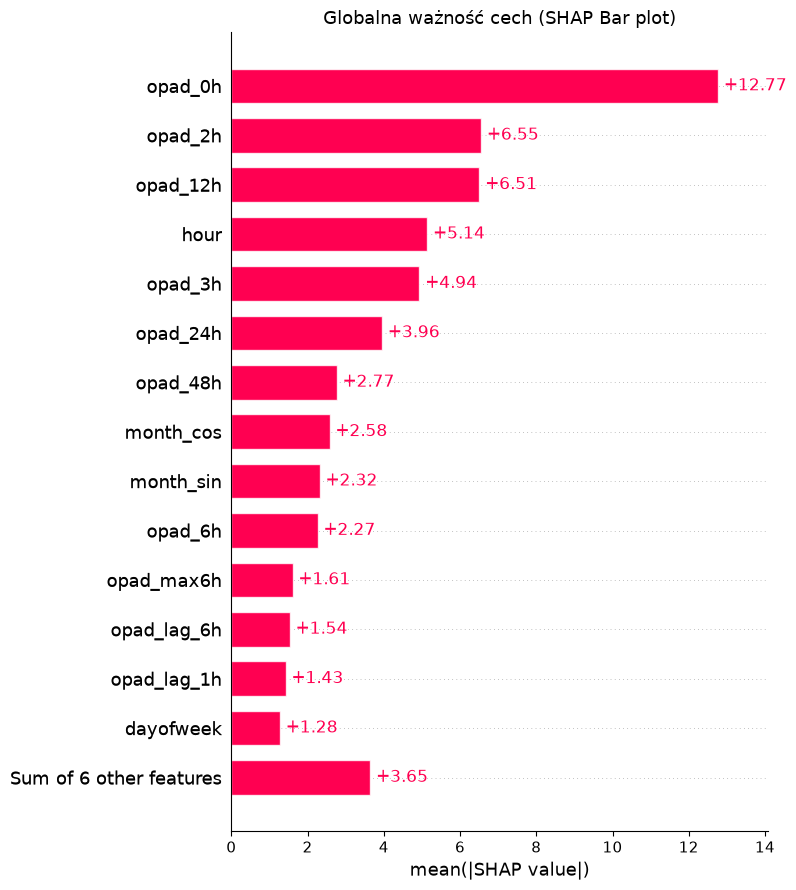

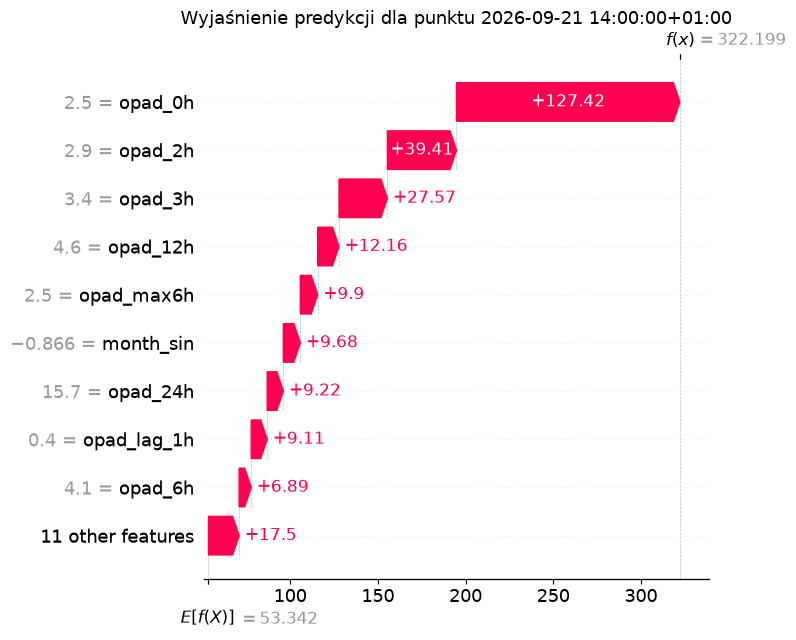

In [107]:
generate_shap_from_tree(cb_q97,X_test,date_with_time="2026-09-21 14:00:00")

# OPTUNA DOSTRAJANIE


In [108]:
import numpy as np
import optuna
from catboost import CatBoostRegressor

# STROJENIE MODELU MEDIANOWEGO (cb_median)
def objective_median(trial):
    params = {
        'loss_function': 'MAE',
        'eval_metric': 'MAE',
        'iterations': 1500,
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'depth': trial.suggest_int('depth', 4, 8),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1.0, 20.0),
        'random_strength': trial.suggest_float('random_strength', 1e-3, 5.0),
        'task_type': 'CPU',
        'random_seed': 42,
        'verbose': 0
    }

    model = CatBoostRegressor(**params, early_stopping_rounds=40)
    model.fit(X_train, y_train, eval_set=(X_val, y_val), use_best_model=True)

    preds = model.predict(X_val)
    mae = np.mean(np.abs(y_val - preds))
    return mae

study_median = optuna.create_study(direction="minimize")
study_median.optimize(objective_median, n_trials=40)
print("Najlepsze parametry dla Median:", study_median.best_params)


# STROJENIE MODELU KWANTYLOWEGO (cb_q97)
def pinball_loss(y_true, y_pred, alpha=0.97):
    err = y_true - y_pred
    return np.mean(np.maximum(alpha * err, (alpha - 1.0) * err))

def objective_q97(trial):
    params = {
        'loss_function': 'Quantile:alpha=0.97',
        'eval_metric': 'Quantile:alpha=0.97',
        'iterations': 1500,
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'depth': trial.suggest_int('depth', 4, 8),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1.0, 20.0),
        'random_strength': trial.suggest_float('random_strength', 1e-3, 5.0),
        'task_type': 'CPU',
        'random_seed': 42,
        'verbose': 0
    }

    model = CatBoostRegressor(**params, early_stopping_rounds=40)
    model.fit(X_train, y_train, eval_set=(X_val, y_val), use_best_model=True)

    q_preds = model.predict(X_val)

    #Błąd Pinball
    loss = pinball_loss(y_val, q_preds, alpha=0.97)

    #Kara za uciekanie od Coverage = 97%
    empirical_coverage = np.mean(y_val <= q_preds)
    coverage_penalty = np.abs(empirical_coverage - 0.97) * 5.0

    return loss + coverage_penalty

study_q97 = optuna.create_study(direction="minimize")
study_q97.optimize(objective_q97, n_trials=40)
print("Najlepsze parametry dla Q97:", study_q97.best_params)

[I 2026-10-27 17:28:01,729] A new study created in memory with name: no-name-88684deb-a1f2-4ef6-b4d0-5c6aad8e15d7
[I 2026-10-27 17:28:02,924] Trial 0 finished with value: 6.9089640758842235 and parameters: {'learning_rate': 0.02901065256988983, 'depth': 7, 'l2_leaf_reg': 11.912349660297464, 'random_strength': 4.162925223505981}. Best is trial 0 with value: 6.9089640758842235.
[I 2026-10-27 17:28:03,437] Trial 1 finished with value: 7.036603746015697 and parameters: {'learning_rate': 0.08171792774524643, 'depth': 8, 'l2_leaf_reg': 8.224872285257028, 'random_strength': 0.5342352244498287}. Best is trial 0 with value: 6.9089640758842235.
[I 2026-10-27 17:28:04,801] Trial 2 finished with value: 6.889104442463958 and parameters: {'learning_rate': 0.016644767414523694, 'depth': 7, 'l2_leaf_reg': 17.83092614543225, 'random_strength': 0.938368978498701}. Best is trial 2 with value: 6.889104442463958.
[I 2026-10-27 17:28:05,492] Trial 3 finished with value: 7.232434501389541 and parameters: {'l

Najlepsze parametry dla Median: {'learning_rate': 0.02395308557548984, 'depth': 8, 'l2_leaf_reg': 18.111890428922774, 'random_strength': 1.7326548631533165}


[I 2026-10-27 17:28:56,791] Trial 0 finished with value: 1.3254577056277768 and parameters: {'learning_rate': 0.04827794617050587, 'depth': 5, 'l2_leaf_reg': 7.592285596796102, 'random_strength': 1.3326695814926854}. Best is trial 0 with value: 1.3254577056277768.
[I 2026-10-27 17:28:57,385] Trial 1 finished with value: 1.2098585087236233 and parameters: {'learning_rate': 0.022632915534967237, 'depth': 4, 'l2_leaf_reg': 16.513106727680395, 'random_strength': 2.278687372615195}. Best is trial 1 with value: 1.2098585087236233.
[I 2026-10-27 17:28:57,963] Trial 2 finished with value: 1.310794878834065 and parameters: {'learning_rate': 0.03246435373419954, 'depth': 7, 'l2_leaf_reg': 10.797724074190072, 'random_strength': 4.889790895193062}. Best is trial 1 with value: 1.2098585087236233.
[I 2026-10-27 17:28:58,346] Trial 3 finished with value: 1.435408634735024 and parameters: {'learning_rate': 0.07954758836358718, 'depth': 8, 'l2_leaf_reg': 18.417008424997896, 'random_strength': 2.2683525

Najlepsze parametry dla Q97: {'learning_rate': 0.03147367129698738, 'depth': 4, 'l2_leaf_reg': 16.607919430287176, 'random_strength': 1.3042519898533924}


In [109]:
print("Najlepszy wynik median (MAE):", study_median.best_value)
print("Najlepsze parametry median:", study_median.best_params)

print("Najlepszy wynik q97 (MAE):", study_q97.best_value)
print("Najlepsze parametry q97:", study_q97.best_params)

Najlepszy wynik median (MAE): 6.752457250171171
Najlepsze parametry median: {'learning_rate': 0.02395308557548984, 'depth': 8, 'l2_leaf_reg': 18.111890428922774, 'random_strength': 1.7326548631533165}
Najlepszy wynik q97 (MAE): 1.1597993672478308
Najlepsze parametry q97: {'learning_rate': 0.03147367129698738, 'depth': 4, 'l2_leaf_reg': 16.607919430287176, 'random_strength': 1.3042519898533924}


# Sprawdzenie liczby drzew


In [111]:
# CATBOOST
from catboost import CatBoostRegressor


check_median = CatBoostRegressor(
    **study_median.best_params,
    loss_function="MAE",
    eval_metric="MAE",
    iterations=2500,
    early_stopping_rounds=50,
    task_type="CPU",
    thread_count=-1,
    random_seed=42,
    verbose=100
)
check_median.fit(
    X_train, y_train,
    eval_set=(X_val, y_val),
    use_best_model=True
)


best_trees = check_median.get_best_iteration()
print(f"Optymalna liczba iteracji: {best_trees}")

0:	learn: 11.8450487	test: 9.3696830	best: 9.3696830 (0)	total: 4.48ms	remaining: 11.2s
100:	learn: 8.9835873	test: 7.1504073	best: 7.1504073 (100)	total: 355ms	remaining: 8.44s
200:	learn: 8.3591094	test: 6.8596269	best: 6.8596269 (200)	total: 667ms	remaining: 7.63s
300:	learn: 8.0750236	test: 6.8116524	best: 6.8091865 (298)	total: 982ms	remaining: 7.17s
400:	learn: 7.8203707	test: 6.7861123	best: 6.7835489 (398)	total: 1.3s	remaining: 6.79s
500:	learn: 7.4728171	test: 6.7659989	best: 6.7524563 (457)	total: 1.65s	remaining: 6.57s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 6.752456253
bestIteration = 457

Shrink model to first 458 iterations.
Optymalna liczba iteracji: 457


In [113]:
from catboost import CatBoostRegressor


check_q97 = CatBoostRegressor(
    **study_q97.best_params,
    loss_function="Quantile:alpha=0.97",
    eval_metric="Quantile:alpha=0.97",
    iterations=2500,
    early_stopping_rounds=50,
    task_type="CPU",
    thread_count=-1,
    random_seed=42,
    verbose=0
)

check_q97.fit(
    X_train, y_train,
    eval_set=(X_val, y_val),
    use_best_model=True)

best_trees_q97 = check_q97.get_best_iteration()
print(f"Optymalna liczba iteracji dla q97 to: {best_trees_q97}")

Optymalna liczba iteracji dla q97 to: 336


In [114]:
print(f"Średni przepływ TRAIN: {y_train.mean():.2f} (std: {y_train.std():.2f})")
print(f"Średni przepływ TEST:  {y_test.mean():.2f} (std: {y_test.std():.2f})")

Średni przepływ TRAIN: 25.55 (std: 32.55)
Średni przepływ TEST:  23.62 (std: 34.87)
